   taille_en_pieds_carre  nb_chambres    prix
0                   2104            3  399900
1                   1600            3  329900
2                   2400            3  369000
3                   1416            2  232000
4                   3000            4  539900
       taille_en_pieds_carre  nb_chambres           prix
count              47.000000    47.000000      47.000000
mean             2000.680851     3.170213  340412.659574
std               794.702354     0.760982  125039.899586
min               852.000000     1.000000  169900.000000
25%              1432.000000     3.000000  249900.000000
50%              1888.000000     3.000000  299900.000000
75%              2269.000000     4.000000  384450.000000
max              4478.000000     5.000000  699900.000000


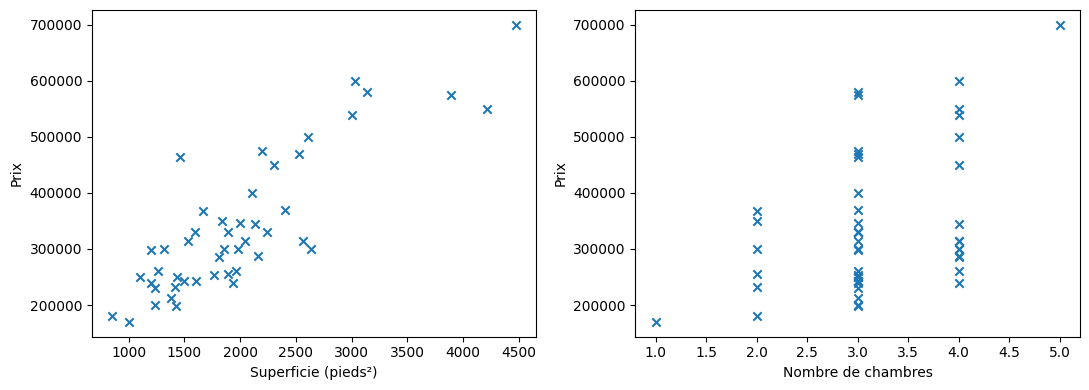

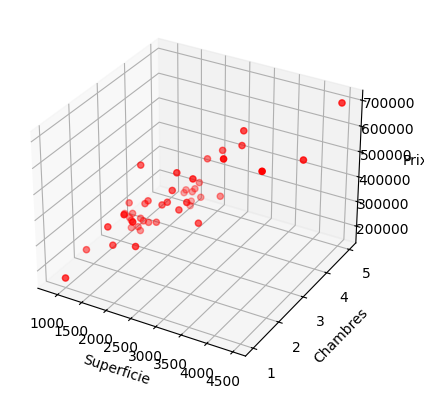

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df = pd.read_excel("C:/Users/USER/PycharmProjects/TP2/Multivaried_Regression/MultivariateLinearRegression.xlsx")
print(df.head())
print(df.describe())

Y = df["prix"]
X = df[['taille_en_pieds_carre', 'nb_chambres']]

# Deux scatter plots 2D
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(df['taille_en_pieds_carre'], Y, marker='x')
ax[0].set_xlabel("Superficie (pieds²)"); ax[0].set_ylabel("Prix")
ax[1].scatter(df['nb_chambres'], Y, marker='x')
ax[1].set_xlabel("Nombre de chambres"); ax[1].set_ylabel("Prix")
plt.tight_layout(); plt.show()

# Scatter plot 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df['taille_en_pieds_carre'], df['nb_chambres'], Y, c='r', marker='o')
ax.set_xlabel("Superficie"); ax.set_ylabel("Chambres"); ax.set_zlabel("Prix")
plt.show()

Interprétations :

1. Prix en fonction de la superficie (graphique en haut à gauche)
Relation positive et approximativement linéaire. Le prix passe d’environ 170 000 pour les plus petites maisons (~900 pieds²) à 700 000 pour la plus grande (~4 500 pieds²). La superficie est un bon prédicteur du prix.
Dispersion modérée. La plupart des points suivent un couloir étroit, mais il reste de la variabilité à superficie égale. Par exemple, autour de 1 500 pieds², les prix vont d’environ 200 000 à 465 000. Une maison à ~1 450 pieds² et ~465 000 s’écarte nettement du nuage (point atypique).
Répartition inégale des données. La majorité des maisons font entre 1 000 et 2 600 pieds². Au-delà de 3 000, il n’y a que quelques points. Le modèle sera donc moins fiable pour les grandes maisons.
Légère saturation possible. Les maisons de ~3 900 et ~4 200 pieds² sont vendues autour de 550 000-575 000, pas plus cher que des maisons de 3 000 pieds² (540 000-600 000). La pente semble faiblir dans les hautes superficies, ce qui pourrait indiquer une relation un peu moins que linéaire. Avec si peu de points, il faut rester prudent.
Point à fort effet de levier. La maison à ~4 500 pieds² et 700 000 est isolée à l’extrémité du nuage. Elle peut tirer la droite de régression vers elle.

2. Prix en fonction du nombre de chambres (graphique en haut à droite)
Variable discrète (1 à 5), donc les points forment des colonnes verticales. Un scatter plot n’est pas idéal pour ce type de variable. Un boxplot par nombre de chambres serait plus lisible.
Effectifs très inégaux. Il n’y a qu’une maison à 1 chambre et qu’une maison à 5 chambres. La plupart des maisons ont 3 chambres (environ la moitié), puis 4 et 2.
Relation faible. Les prix se chevauchent beaucoup d’une colonne à l’autre. Avec 3 chambres, ils vont d’environ 200 000 à 580 000. Savoir seulement le nombre de chambres ne permet donc presque pas de prédire le prix.
Tendance globale légèrement croissante, mais surtout tirée par les deux extrêmes isolés (1 chambre à 170 000, 5 chambres à 700 000). Ce sont deux observations uniques, donc fragiles.
La maison à 5 chambres est la même que celle à 4 500 pieds². Cette seule observation influence à la fois les deux variables.

3. Graphique 3D
Les points suivent une tendance montante quand la superficie et le nombre de chambres augmentent ensemble. Un plan incliné est donc un modèle plausible, ce qui justifie une régression linéaire multiple.
La grande majorité des points est concentrée dans un coin (superficie 1 000-2 500, 2 à 4 chambres, prix 200 000-400 000). Les extrémités sont peu peuplées.
Dans la vue 3D, l’axe de la superficie domine visuellement la variation du prix. Celui des chambres apporte peu en plus.

### Q4 : Analyse exploratoire complémentaire
Corrélations entre variables, distribution du prix par nombre de chambres, et effectifs par modalité.

                       taille_en_pieds_carre  nb_chambres      prix
taille_en_pieds_carre               1.000000     0.559967  0.854988
nb_chambres                         0.559967     1.000000  0.442261
prix                                0.854988     0.442261  1.000000


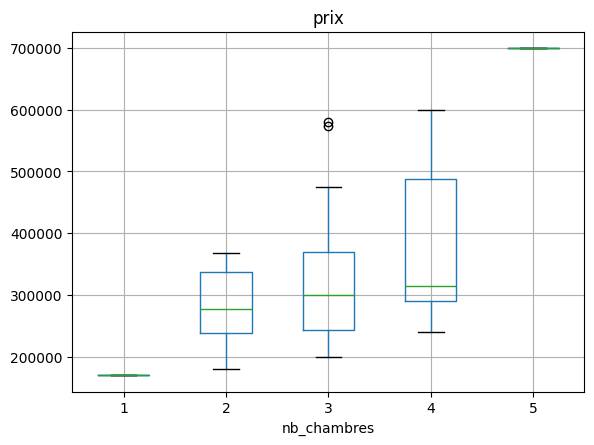

nb_chambres
1     1
2     6
3    25
4    14
5     1
Name: count, dtype: int64


In [3]:
print(df.corr())                                   # corrélations superficie / chambres / prix
df.boxplot(column='prix', by='nb_chambres')        # prix selon le nombre de chambres
plt.suptitle(""); plt.show()
print(df['nb_chambres'].value_counts().sort_index())

### Q4 (suite) : Régression linéaire multivariée
1. Normalisation des variables prédictives (StandardScaler).
2. Entraînement du modèle par moindres carrés ordinaires (OLS), avec une constante.
3. Lecture du résumé statistique et prédiction d'un nouveau cas.

[[ 0.13141542 -0.22609337]
 [-0.5096407  -0.22609337]
 [ 0.5079087  -0.22609337]
 [-0.74367706 -1.5543919 ]
 [ 1.27107075  1.10220517]]
                            OLS Regression Results                            
Dep. Variable:                   prix   R-squared:                       0.733
Model:                            OLS   Adj. R-squared:                  0.721
Method:                 Least Squares   F-statistic:                     60.38
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           2.43e-13
Time:                        11:30:17   Log-Likelihood:                -586.77
No. Observations:                  47   AIC:                             1180.
Df Residuals:                      44   BIC:                             1185.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.

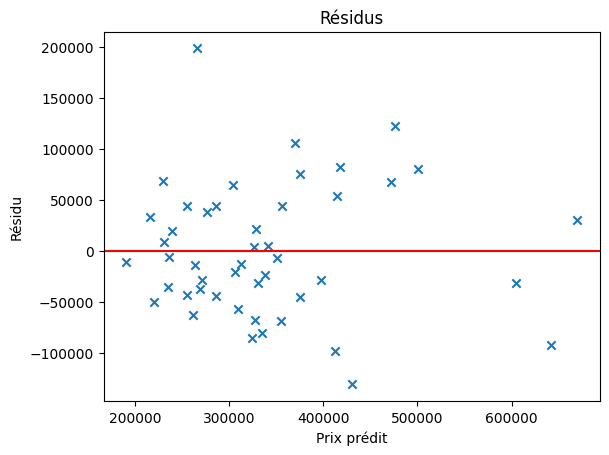

In [4]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1) Normalisation (moyenne 0, écart-type 1)
scale = StandardScaler()
X_scaled = scale.fit_transform(X.values)          # .values remplace .as_matrix()
print(X_scaled[:5])

# 2) Modèle OLS avec constante (ordonnée à l'origine)
X_sm = sm.add_constant(X_scaled)
model = sm.OLS(Y, X_sm).fit()
print(model.summary())

# Noms lisibles pour les coefficients
print(dict(zip(['const', 'superficie', 'chambres'], model.params)))

# 3) Multicolinéarité : VIF (un VIF > 5 signale un problème)
for i, nom in enumerate(X.columns):
    print(nom, variance_inflation_factor(X_scaled, i))

# 4) Prédiction d'une maison de 4500 pieds² et 5 chambres
def predict_price_of_house(taille_maison, nb_chambre):
    nouvelle = scale.transform([[taille_maison, nb_chambre]])   # même scaler que l'entraînement
    nouvelle = sm.add_constant(nouvelle, has_constant='add')
    return model.predict(nouvelle)[0]

print(predict_price_of_house(4500, 5))

# 5) Qualité : valeurs prédites et résidus
Y_pred = model.predict(X_sm)
residus = Y - Y_pred
plt.scatter(Y_pred, residus, marker='x')
plt.axhline(0, c='r')
plt.xlabel("Prix prédit"); plt.ylabel("Résidu"); plt.title("Résidus")
plt.show()